# 🚀 Sprint 4 — Evaluation & Deployment
**Entrada:** artefactos dos Sprints 2 e 3 · **Saída:** `models/best_classifier.joblib` (+ sistema multiagente em `src/agent.py`)

In [1]:
import os, sys, glob, time, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, os.path.abspath("src"))   # executar o notebook na raiz do projeto (onde está a pasta src/)

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

S = joblib.load("data/splits.joblib"); CFG = joblib.load("data/config.joblib")
X_test, y_test, le = S["X_test"], S["y_test"], S["label_encoder"]
CONTRACT = CFG["CONTRACT"]
preps = {"sparse": joblib.load("models/prep_sparse.joblib"), "dense": joblib.load("models/prep_dense.joblib")}
F = joblib.load("models/fitted_models.joblib"); fitted, prep_kind = F["fitted"], F["prep_kind"]
res = pd.read_csv("reports/model_comparison.csv"); res

,model,accuracy,f1_macro,fit_time_s,pred_time_s
0,XGBoost,0.983359,0.983605,46.87,0.02
1,LogisticRegression,0.983359,0.983572,3.07,0.01
2,SVC RBF (SVM não-linear),0.982743,0.982996,10.93,4.27
3,LinearSVC (SVM linear),0.982126,0.982212,7.96,0.01
4,GradientBoosting (Hist),0.980277,0.980666,12.03,0.06
5,kNN (cosine),0.979661,0.980186,0.01,4.40
6,RandomForest (bagging),0.979353,0.979781,23.85,0.32
7,MultinomialNB,0.978120,0.978838,0.05,0.01
8,BernoulliNB,0.977812,0.978386,0.06,0.02
9,GaussianNB,0.967334,0.967886,0.21,0.30


## 4.1 Avaliação final do melhor modelo (teste)
Escolhemos o melhor entre os modelos **scikit-learn** (para empacotar num único pipeline com pré-processamento); o TensorFlow fica em `models/` e entra na comparação do Sprint 3.

Melhor modelo: XGBoost
TESTE -> accuracy=0.9815 | F1-macro=0.9817

              precision    recall  f1-score   support

      Arabic      1.000     0.993     0.997       149
     Chinese      0.980     1.000     0.990       150
       Dutch      0.980     0.980     0.980       148
     English      0.856     0.993     0.920       150
    Estonian      0.979     0.946     0.962       149
      French      0.980     0.993     0.986       147
       Hindi      1.000     0.986     0.993       145
  Indonesian      1.000     0.972     0.986       145
    Japanese      1.000     0.973     0.986       150
      Korean      1.000     0.987     0.993       150
       Latin      0.937     0.937     0.937       142
     Persian      1.000     0.993     0.997       147
  Portuguese      0.979     0.973     0.976       147
      Pushto      0.993     0.964     0.978       140
    Romanian      0.993     0.987     0.990       150
     Russian      0.980     1.000     0.990       148
     Spanish  

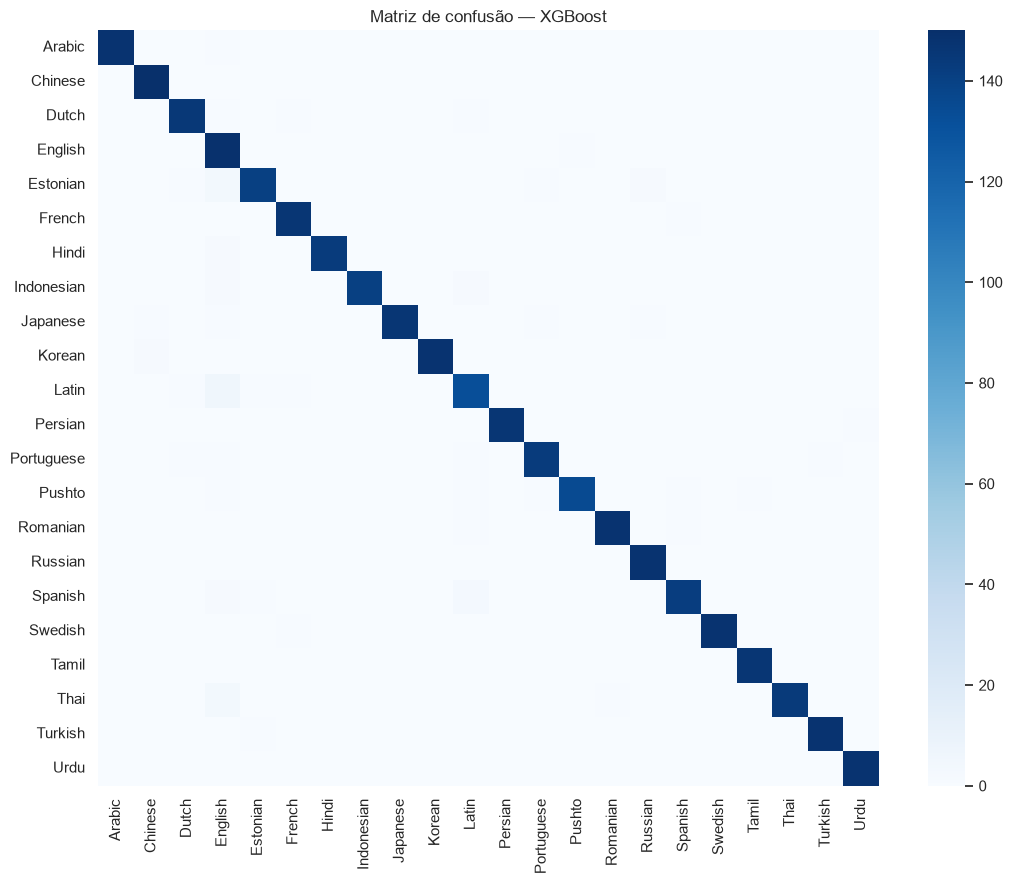

Top confusões (real -> previsto): [('Latin', 'English', 6), ('Estonian', 'English', 4), ('Thai', 'English', 4), ('Spanish', 'Latin', 3), ('Estonian', 'Russian', 2), ('Hindi', 'English', 2), ('Indonesian', 'English', 2), ('Indonesian', 'Latin', 2)]
Guardado em models/best_classifier.joblib


In [3]:
sk_res = res[res["model"] != "TensorFlow MLP"]
best_name = sk_res.iloc[0]["model"]
best_prep = preps[prep_kind[best_name]]
pred_test = fitted[best_name].predict(best_prep.transform(X_test))
print(f"Melhor modelo: {best_name}")
print(f"TESTE -> accuracy={accuracy_score(y_test, pred_test):.4f} | F1-macro={f1_score(y_test, pred_test, average='macro'):.4f}\n")
print(classification_report(y_test, pred_test, target_names=le.classes_, digits=3))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
ax.set_title(f"Matriz de confusão — {best_name}"); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(le.classes_[i], le.classes_[j], int(cm_off[i, j])) for i, j in zip(*np.nonzero(cm_off))]
print("Top confusões (real -> previsto):", sorted(pairs, key=lambda t: -t[2])[:8])

best_pipeline = Pipeline([("prep", best_prep), ("clf", fitted[best_name])])
joblib.dump({"pipeline": best_pipeline, "label_encoder": le,
             "metadata": {"model": best_name, "f1_macro_test": float(f1_score(y_test, pred_test, average="macro")),
                          "classes": list(le.classes_), "contract": CONTRACT}}, "models/best_classifier.joblib")
print("Guardado em models/best_classifier.joblib")

## 4.2 Casos extremos (qualidade — CRISP-ML(Q))
Verificamos se a **confiança desce** em entradas problemáticas; é o sinal que o monitor do agente usa para alertar.

In [4]:
from agent import ClassifierAgent, ReporterAgent, NotifierAgent, Orchestrator
clf_agent = ClassifierAgent("models/best_classifier.joblib", low_conf=0.5)
edge_cases = {"texto normal": X_test[0], "muito curto (1 palavra)": "hello", "vazio": "", "só números": "123 456 789",
              "só pontuação": "?!?! ... ,,,", "gibberish": "asdkjh qwpoei zmxncb", "URL": "https://www.example.com/page",
              "texto misto": "Hello, bonjour, hola, olá, ciao"}
rows = []
for k, v in edge_cases.items():
    p = clf_agent.predict(v)[0]
    rows.append({"caso": k, "previsão": p["language"], "confiança": round(p["confidence"], 3), "flag baixa conf.": p["low_confidence"]})
pd.DataFrame(rows)

,caso,previsão,confiança,flag baixa conf.
0,texto normal,Russian,1.000,False
1,muito curto (1 palavra),Tamil,0.447,True
2,vazio,Korean,0.431,True
3,só números,Korean,0.431,True
4,só pontuação,Korean,0.431,True
5,gibberish,Tamil,0.415,True
6,URL,Korean,0.431,True
7,texto misto,Thai,0.986,False


## 4.3 Sistema multiagente — arquitetura
```mermaid
flowchart LR
    U[Utilizador / Stream de textos] --> O[Orquestrador]
    O -->|skill: classify| C[ClassifierAgent<br/>models/best_classifier.joblib]
    C -->|previsões + confiança| O
    O -->|estatísticas| R[ReporterAgent<br/>LLM Transformers / Unsloth]
    R -->|relatório| O
    O -->|alertas + dashboard| N[NotifierAgent<br/>Telegram]
    N --> T[(Telegram do operador)]
    M[(models/)] --- C
```
*(Cola o bloco em https://mermaid.live para exportar a imagem para o relatório.)*

**Casos de uso a documentar:**
1. *Classificação em tempo real:* utilizador envia texto → idioma + confiança + top-3.
2. *Monitorização diária:* orquestrador processa o lote → relatório do LLM → dashboard por Telegram → alerta se houver muita baixa confiança ou idiomas novos (*drift*).

In [5]:
# ---- Simulação: dia normal vs. dia com problemas ----
rng = np.random.default_rng(RANDOM_STATE)
normal_day = list(rng.choice(X_test, 200, replace=False))

def corrupt(t):
    mode = rng.integers(0, 3)
    if mode == 0: return " ".join(t.split()[:1])                                   # truncado
    if mode == 1: return "".join(rng.choice(list("abcdefghij0123456789?!"), 12))   # ruído
    return ""                                                                       # vazio
noisy_day = [corrupt(t) if rng.random() < 0.5 else t for t in normal_day]

reporter = ReporterAgent(use_llm=False)      # True -> LLM via Hugging Face
notifier = NotifierAgent()                   # define TELEGRAM_TOKEN / TELEGRAM_CHAT_ID para envio real
orch = Orchestrator(clf_agent, reporter, notifier, max_low_conf=0.25, baseline=list(le.classes_))
print("=== DIA NORMAL ==="); _ = orch.daily_dashboard(normal_day)
print("\n=== DIA COM PROBLEMAS ==="); _ = orch.daily_dashboard(noisy_day)

=== DIA NORMAL ===
[Telegram DRY-RUN]
📊 Dashboard diário
Relatório de identificação de idioma
- Textos analisados: 200
- Idiomas mais frequentes: [('Hindi', 16), ('Urdu', 14), ('Korean', 13), ('Turkish', 13), ('Chinese', 12)]
- Confiança média: 0.997
- % com baixa confiança: 0.0%

✅ Sem alertas

=== DIA COM PROBLEMAS ===
[Telegram DRY-RUN]
📊 Dashboard diário
Relatório de identificação de idioma
- Textos analisados: 200
- Idiomas mais frequentes: [('Korean', 43), ('Hindi', 15), ('Tamil', 15), ('Thai', 10), ('Portuguese', 10)]
- Confiança média: 0.78
- % com baixa confiança: 30.0%

⚠️ 30% das predições com baixa confiança (limite 25%)


### Notas: parte generativa e segunda versão do multiagente
- **LLM local:** `ReporterAgent(use_llm=True)` usa `transformers`. Para *fine-tuning*/inferência rápida usa **Unsloth** (`FastLanguageModel.from_pretrained("unsloth/Qwen2.5-0.5B-Instruct")`) num ambiente com GPU (Colab).
- **Telegram:** cria um bot com o *@BotFather* e define `TELEGRAM_TOKEN` e `TELEGRAM_CHAT_ID`.
- **Segunda versão (requisito):** reimplementar em **CrewAI** ou **n8n/Langflow** com as mesmas *skills* e comparar no relatório.

In [ ]:
# ---- Esqueleto CrewAI (opcional; pip install crewai) ----
# from crewai import Agent, Task, Crew
# from crewai.tools import tool
#
# @tool("classify_language")
# def classify_language(text: str) -> str:
#     "Identifica o idioma de um texto e devolve idioma e confiança."
#     p = clf_agent.predict(text)[0]
#     return f"{p['language']} ({p['confidence']:.2f})"
#
# analyst  = Agent(role="Analista de idiomas", goal="Classificar textos", backstory="...", tools=[classify_language])
# reporter = Agent(role="Redator", goal="Escrever relatório diário", backstory="...")
# crew = Crew(agents=[analyst, reporter], tasks=[Task(description="Classifica: ...", agent=analyst, expected_output="lista")])
# crew.kickoff()

## 4.4 Execução integrada (carrega tudo a partir de `models/`)

In [6]:
print("Modelos em models/:", os.listdir("models"))
clf_agent = ClassifierAgent("models/best_classifier.joblib")
demo = ["Hello, how are you today?", "Bom dia, como está?", "Wie geht es dir heute?", "Je voudrais un café, s'il vous plaît"]
for p in clf_agent.predict(demo):
    print(f"{p['text']!r:45} -> {p['language']:12} conf={p['confidence']:.2f} top3={p['top3']}")

Modelos em models/: ['best_classifier.joblib', 'fitted_models.joblib', 'prep_dense.joblib', 'prep_sparse.joblib']
'Hello, how are you today?'                   -> Turkish      conf=0.37 top3=[('Turkish', 0.371), ('Thai', 0.288), ('English', 0.243)]
'Bom dia, como está?'                         -> Portuguese   conf=0.97 top3=[('Portuguese', 0.971), ('Latin', 0.012), ('Spanish', 0.007)]
'Wie geht es dir heute?'                      -> Dutch        conf=1.00 top3=[('Dutch', 0.999), ('English', 0.0), ('Turkish', 0.0)]
"Je voudrais un café, s'il vous plaît"        -> Estonian     conf=0.52 top3=[('Estonian', 0.517), ('Tamil', 0.094), ('Japanese', 0.061)]


## 5. Conclusões e checklist para a defesa oral
**Preencher:** melhor modelo, F1-macro no teste, principais confusões (idiomas próximos), comportamento em casos extremos, trade-offs (TF-IDF de caracteres vs. embeddings; SVD vs. esparso; `class_weight` vs. SMOTE).

**3–4 componentes para explicar sem notas:**
1. `prep_sparse` (Sprint 2) — porquê *char n-grams* + chi2 + MaxAbsScaler, ajustado só no treino (anti-leakage).
2. `evaluate_model` e o critério F1-macro na validação (teste usado uma só vez).
3. `ClassifierAgent._proba` — softmax sobre `decision_function` quando não há `predict_proba`.
4. `Orchestrator.process_batch` — regras de alerta (baixa confiança e *drift* de idiomas).

**Trabalho futuro:** monitorização contínua, novos idiomas, *fine-tuning* com Unsloth, API (FastAPI) + Telegram.